# Постобработка OCR паспорта РФ

## 1. Ставлю задачу и фиксирую критерии

Получаю результат OCR и выбираю `accept` или `reject`. Для принятого документа
возвращаю все 10 полей. Считаю ответ правильным, если все поля совпадают с эталоном
и паспорт проходит доступные проверки срока действия на **01.10.2026**.

Использую два уровня: сначала восстанавливаю поля, затем оцениваю надёжность всего ответа.
Для буквального приоритета задания выбираю осторожный режим `strict`. Для неизвестной
цены ошибок отдельно исследую сценарии, в которых FP дороже FN в 5, 10 и 25 раз.

В итоговой внутренней проверке strict принимаю 27 из 3000 документов без FP;
низкий охват 0.9% сохраняю как главное ограничение. Экономический режим 25× даёт
охват 57.0% и 25 FP. Эти два результата не подменяю друг другом.

Работаю с сохранёнными локальными моделями и результатами CV. Запускаю ноутбук
из каталога проекта. Для полного пересчёта переключаю `RUN_VALIDATION=True`;
при этом заново обучаю модели через тот же `train.py`, а не дублирую реализацию в ячейках.

In [1]:
import hashlib
import json
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from passport_ocr import FIELDS, norm, read_jsonl, validity_reason, visual_fields, wrong_fields
from postprocess import PassportProcessor
from train import economic_metrics, economic_model_grid, make_risk_pipeline, prepare_data

ROOT = Path.cwd()
RUN_VALIDATION = False
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 75)

if RUN_VALIDATION:
    subprocess.run([sys.executable, str(ROOT / 'train.py'), '--validate'], check=True)

manifest = json.loads((ROOT / 'artifacts/model_manifest.json').read_text(encoding='utf-8'))
cached_summary = json.loads((ROOT / 'artifacts/research_summary.json').read_text(encoding='utf-8'))
assert cached_summary['input_sha256'] == manifest['input_sha256'], 'Пересчитываю кэш через train.py --validate'
for filename, expected in manifest['input_sha256'].items():
    actual = hashlib.sha256((ROOT / filename).read_bytes()).hexdigest()
    assert actual == expected, f'Меняются исходные данные: {filename}'
actual_model_hash = hashlib.sha256((ROOT / 'artifacts/models.joblib').read_bytes()).hexdigest()
assert actual_model_hash == manifest['model_sha256']
print('Python:', sys.version.split()[0])
print('numpy:', np.__version__, 'pandas:', pd.__version__, 'scikit-learn:', sklearn.__version__)
print('Дата проверки:', manifest['as_of'])

Python: 3.11.16
numpy: 2.4.6 pandas: 3.1.0 scikit-learn: 1.9.1
Дата проверки: 2026-10-01


## 2. Загружаю данные и проверяю состав

Использую 3000 документов train с эталонами и 2000 документов test без разметки.
Отдельного готового val в пакете не получаю. Для проверки выделяю части train,
причём повторы одного паспорта держу в одной группе по эталонной серии и номеру.
Сам номер, ID и тексты ФИО в признаки модели не передаю.

In [2]:
train_docs = read_jsonl(ROOT / 'data/train_predictions.jsonl')
test_docs = read_jsonl(ROOT / 'data/test_predictions.jsonl')
labels = {row['doc_id']: row['fields'] for row in read_jsonl(ROOT / 'data/train_labels.jsonl')}
assert len(train_docs) == 3000 and len(test_docs) == 2000
assert {doc['doc_id'] for doc in train_docs} == set(labels)
assert not {doc['doc_id'] for doc in train_docs} & {doc['doc_id'] for doc in test_docs}
assert all(set(doc['viz']) == set(FIELDS) for doc in train_docs + test_docs)

source_table = pd.DataFrame({
    'train': pd.Series([doc['source'] for doc in train_docs]).value_counts(),
    'test': pd.Series([doc['source'] for doc in test_docs]).value_counts()
})
source_table['train_share'] = source_table['train'] / len(train_docs)
source_table['test_share'] = source_table['test'] / len(test_docs)
display(source_table.round(3))
print('Уникальных паспортов:', manifest['unique_passports'])
print('Train без MRZ:', sum(doc['mrz'] is None for doc in train_docs))
print('Test без MRZ:', sum(doc['mrz'] is None for doc in test_docs))

,train,test,train_share,test_share
web,1639,890,0.546,0.445
mobile,1069,679,0.356,0.340
mobile_v2,292,431,0.097,0.216


Уникальных паспортов: 2994
Train без MRZ: 183
Test без MRZ: 106


Замечаю увеличение доли `mobile_v2` в test с 9.7% до 21.6%.
Поэтому качество дополнительно смотрю по источникам, а прогноз ошибок
перевзвешиваю под состав принимаемых документов test.

## 3. Измеряю baseline и ошибки по полям

В baseline объединяю OCR-строки и нормализую регистр и повторные пробелы,
как в `evaluate.py`. Пунктуацию, одиночные пробелы и различие `Е`/`Ё` сохраняю.
Разделяю точное совпадение полей и совпадение с дополнительной проверкой дат.

Все 10 полей исходного OCR совпадают: 1680 из 3000


,stage,exact_fields,safe
0,OCR: объединение строк,1680,1624
1,MRZ и форматы,1880,1819
2,Полная постобработка,1975,1910


,before,after
field,,
Issue_organization_ru,602,447
Birth_place_ru,519,519
Licence_number,156,96
Middle_name_ru,140,116
Last_name_ru,136,104
Birth_date,124,68
Issue_date,113,51
Issue_organisation_code,108,52
First_name_ru,96,78


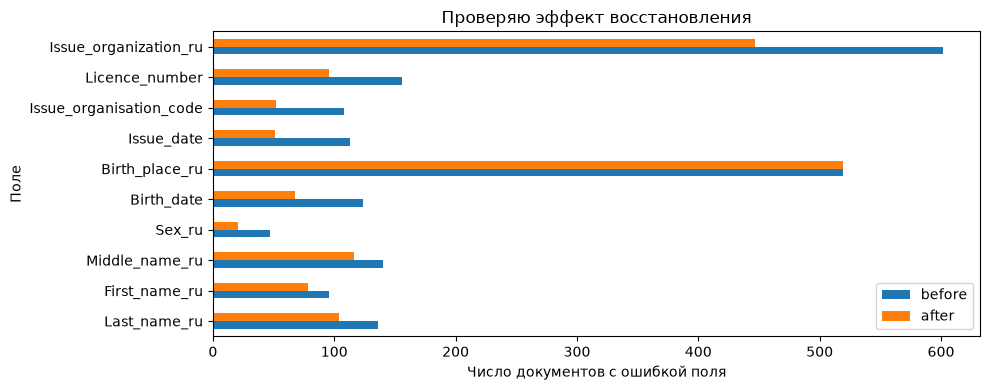

In [3]:
data = prepare_data(ROOT)
candidates = data['candidates']
raw_correct = 0
for doc in train_docs:
    raw_correct += not wrong_fields(visual_fields(doc), labels[doc['doc_id']])
print('Все 10 полей исходного OCR совпадают:', raw_correct, 'из', len(train_docs))

recovery = pd.read_csv(ROOT / 'artifacts/recovery_summary.csv')
display(recovery)
field_errors = pd.read_csv(ROOT / 'artifacts/field_errors.csv').set_index('field')
display(field_errors.sort_values('before', ascending=False))
field_errors[['before', 'after']].plot.barh(figsize=(10, 4))
plt.xlabel('Число документов с ошибкой поля')
plt.ylabel('Поле')
plt.title('Проверяю эффект восстановления')
plt.tight_layout()
plt.show()

## 4. Восстанавливаю только проверяемые изменения

Использую общую реализацию `passport_ocr.py`, которую вызываю и из ноутбука,
и из итогового скрипта. Собираю строки по координатам, проверяю полноту по геометрии,
разбираю MRZ и проверяю контрольные цифры. Восстанавливаю цифровые поля по согласованной
нижней строке; для простой полной записи ФИО использую обратную кодировку MRZ.
Составные и обрезанные имена автоматически не дописываю.

В органе выдачи исправляю одну букву с уверенностью ниже 0.9, если по коду подразделения
нахожу единственное подходящее слово той же длины. Падежи и сокращения по справочнику
не переписываю. Латинские слова целиком сохраняю, омоглифы заменяю только внутри
смешанного кириллического слова. Исправлением точек в датах не угадываю отсутствующие цифры.

В итоге увеличиваю число правильных ответов с допустимыми датами с 1819 до 1910.
Полностью восстанавливаю поля ещё у 95 документов, из которых 91 проходит проверку дат;
ранее полностью правильные ответы на этом train не порчу.

In [4]:
changed_examples = []
for doc, candidate in zip(train_docs, candidates):
    original = visual_fields(doc)
    for field in FIELDS:
        if original[field] != candidate['fields'][field]:
            changed_examples.append({
                'doc_id': doc['doc_id'], 'field': field,
                'before': original[field], 'after': candidate['fields'][field]
            })
display(pd.DataFrame(changed_examples).head(6))

,doc_id,field,before,after
0,tr_00004,Middle_name_ru,ММИХАЙЛСВИЧ,ММИХАЙЛОВИЧ
1,tr_00009,Issue_organization_ru,ГУ ЫМВД РОССИИ ПО КЕМЕРСВСКОЙ ОБЛ,ГУ ЫМВД РОССИИ ПО КЕМЕРОВСКОЙ ОБЛ
2,tr_00010,Issue_organisation_code,,380-046
3,tr_00017,Birth_date,22.03.1088,22.03.1988
4,tr_00022,Issue_organization_ru,УМВЛ РОССИИ ПО НОВГОРОДСКОЙ ОБЛ,УМВД РОССИИ ПО НОВГОРОДСКОЙ ОБЛ
5,tr_00026,Licence_number,07 12 905785,07 12 905285


## 5. Проверяю даты и задаю целевую метку

Проверяю существование дат, выдачу не раньше 14-летия, отсутствие будущей даты выдачи
и необходимость замены в 20 и 45 лет с учётом 90 дней.
Опираюсь на [пункт 24 Положения о паспорте](https://www.consultant.ru/document/cons_doc_LAW_466454/6125ca6a5baabbd3bbff7302f2c6e114b94061fa/).
По этим полям не устанавливаю утрату, аннулирование или выдачу нового паспорта;
полную юридическую действительность без реестра не подтверждаю.

Готовую метку accept/reject в разметке не получаю. Формирую `safe = 1`, когда
все восстановленные поля совпадают с эталоном и эталон проходит доступные проверки дат.
Иначе присваиваю `safe = 0`. Для модели поля использую точное совпадение этого поля.
Все десять полей одного паспорта держу в одной части выборки.

In [5]:
y = data['document_targets']['field']
display(pd.Series(y).value_counts().rename_axis('safe').to_frame('documents'))
date_reasons = pd.Series([
    validity_reason(labels[doc['doc_id']]) or 'passes_available_checks'
    for doc in train_docs
]).value_counts()
display(date_reasons.to_frame('documents'))

,documents
safe,
1,1910
0,1090


,documents
passes_available_checks,2910
expired_20,78
expired_45,12


## 6. Собираю повторяемый Pipeline

Для каждого документа создаю десять строк с признаками полей. Использую уверенности
поля и символов, геометрию и число строк, насыщение уверенности, длину текста,
качество снимка, источник, поддержку MRZ и сходство органа выдачи со справочником.
Получаю 30 000 строк с 24 признаками, но число независимых паспортов не увеличиваю.

В Pipeline объединяю заполнение пропусков, масштабирование числовых признаков,
OneHotEncoder для источника и типа поля и классификатор.
Преобразования обучаю только на соответствующей обучающей части.
Десять score агрегирую минимумом или произведением; произведение использую
для ранжирования и не считаю доказанной вероятностью правильности всего документа.

In [6]:
from sklearn.ensemble import RandomForestClassifier

field_table = data['tables']['field']
display(field_table.head(4))
example_pipeline = make_risk_pipeline(field_table, RandomForestClassifier(
    n_estimators=160, max_depth=10, min_samples_leaf=10,
    max_features=0.8, random_state=42, n_jobs=4
))
display(example_pipeline)

,conf,char_min,char_mean,saturated,height_ratio,line_count,alignment_ok,sharpness,doc_px,glare,...,format_repair,mrz_conflict,mrz_valid,length,empty,reference_repairs,reference_known_code,reference_exact_name,reference_similarity,reference_margin
0,0.9996,0.9985,0.999567,0.111111,1.142857,1,True,198.5,1714,0.101,...,False,False,True,9,False,0,0,0,0.0,0.0
1,0.9992,0.9976,0.999229,0.000000,1.103448,1,True,198.5,1714,0.101,...,False,False,True,7,False,0,0,0,0.0,0.0
2,0.9991,0.9958,0.999145,0.181818,1.000000,1,True,198.5,1714,0.101,...,False,False,True,11,False,0,0,0,0.0,0.0
3,0.9997,0.9993,0.999725,0.250000,1.178571,1,True,198.5,1714,0.101,...,False,False,True,4,False,0,0,0,0.0,0.0


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default

## 7. Сравниваю модели и настраиваю их по экономике

Сравниваю логистическую регрессию, случайный лес и гистограммный бустинг на уровне
документа и полей. У логистической регрессии меняю C; у леса глубину и размер листа;
у бустинга число листьев и L2-регуляризацию. Проверяю 18 конфигураций обучения
и 27 вариантов с учётом агрегации полей.

Точного отношения цены ошибок в условии не получаю. Задаю **5×, 10× и 25× как допущения**,
принимаю стоимость FN за единицу и минимизирую `L = k × FP + FN`.
FP считаю принятием неправильного ответа, FN - отказом от уже правильно восстановленного
документа с допустимыми датами. TP и TN оцениваю нулём.

Для каждого k выбираю семейство, параметры, агрегацию и порог по стоимости на внутренней
calibration-части. Проверяю все уникальные пороги и вариант отклонения всего;
равные score принимаю или отклоняю вместе. При одинаковой стоимости предпочитаю меньше FP.
Разные k между собой по абсолютной стоимости не ранжирую: они задают разные задачи.

In [7]:
trials = pd.read_csv(ROOT / 'artifacts/final_tuning.csv')
trials['family'] = trials['policy'].map(
    lambda name: 'logistic' if 'logistic' in name else 'forest' if 'forest' in name else 'boosting'
)
best_by_family = trials.sort_values(['cal_cost', 'cal_FP', 'cal_FN']).groupby(
    ['ratio', 'family'], as_index=False
).head(1)
display(best_by_family[['ratio', 'family', 'policy', 'threshold', 'cal_FP', 'cal_FN', 'cal_cost']])
print('Сравниваю здесь внутренний отбор; внешнюю оценку показываю далее.')

,ratio,family,policy,threshold,cal_FP,cal_FN,cal_cost
69,5,boosting,field_hist_leaves15_l2_2:minimum,0.859491,7,27,62
54,5,forest,field_forest_depth10_leaf10:product,0.869744,6,36,66
55,10,forest,field_forest_depth10_leaf10:product,0.869744,6,36,96
64,10,boosting,field_hist_leaves7_l2_5:minimum,0.932182,6,37,97
33,5,logistic,field_logistic_C1.0:minimum,0.941435,8,69,109
40,10,logistic,field_logistic_C10.0:minimum,0.958682,5,95,145
65,25,boosting,field_hist_leaves7_l2_5:minimum,0.957105,5,48,173
53,25,forest,field_forest_depth10_leaf10:minimum,0.957628,5,60,185
41,25,logistic,field_logistic_C10.0:minimum,0.963963,4,110,210


Сравниваю здесь внутренний отбор; внешнюю оценку показываю далее.


## 8. Проверяю качество на групповой CV

Использую пять внешних частей. В каждом прогоне сохраняю примерно 20% документов
для проверки, а внутри оставшихся выделяю 25% под calibration.
По внешним документам порог и параметры не подбираю.
Для экономической процедуры каждый документ получает ровно один OOF-прогноз на сценарий.

Для строгого режима обучаю лес на двух третях доступных паспортов, выбираю его
порог на оставшейся трети и требую ноль FP на этой калибровке.
Использую схемы разбиения 142, 143, 144, получаю девять пар «модель - её порог».
Принимаю документ только при согласии всех девяти и прохождении обязательных проверок.
К максимальному score ошибочного калибровочного документа добавляю запас 1e-12,
чтобы не разделять численно одинаковые score по последнему биту float.

Повторяю внешнюю проверку с seed 42, 123 и 2026 и сравниваю 3, 6 и 9 моделей.
Выбираю девять: только этот вариант не даёт FP во всех трёх повторениях.
Все итерации дизайна провожу на знакомом train; эту оценку считаю внутренней,
а не независимой сертификацией. Повторения содержат те же паспорта, поэтому
не считаю их 9000 независимыми документами.

,seed,members,n,accepted,FP,FN,coverage
0,42,3,3000,124,0,1786,0.041333
1,42,6,3000,44,0,1866,0.014667
2,42,9,3000,27,0,1883,0.009000
3,123,3,3000,83,1,1828,0.027667
4,123,6,3000,25,0,1885,0.008333
5,123,9,3000,15,0,1895,0.005000
6,2026,3,3000,99,1,1812,0.033000
7,2026,6,3000,42,1,1869,0.014000
8,2026,9,3000,19,0,1891,0.006333


,ratio,n,accepted,FP,FN,cost,coverage,risk,reject_all_cost
0,5,3000,1809,36,137,317,0.603,0.019900,1910
1,10,3000,1782,30,158,458,0.594,0.016835,1910
2,25,3000,1710,25,225,850,0.570,0.014620,1910


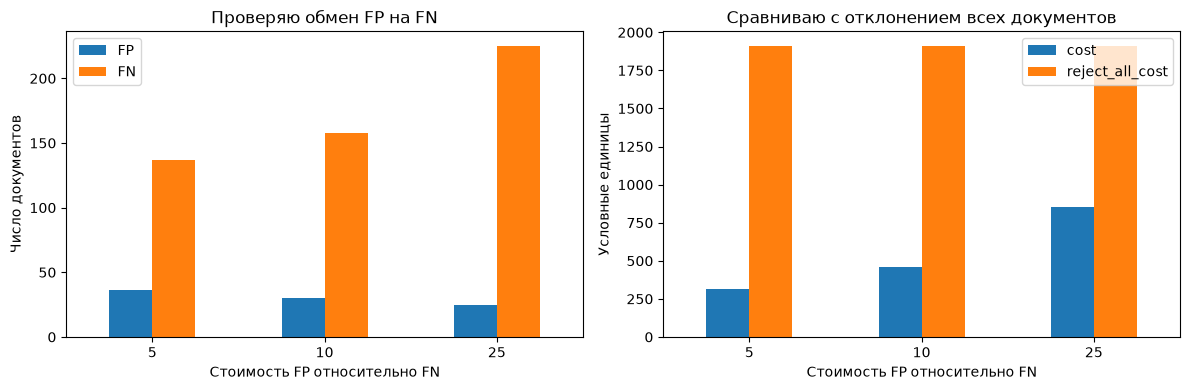

In [8]:
strict_oof = pd.read_csv(ROOT / 'artifacts/strict_oof.csv')
economic_oof = pd.read_csv(ROOT / 'artifacts/economic_oof.csv')
assert strict_oof.groupby(['seed', 'members', 'doc_id']).size().eq(1).all()
assert economic_oof.groupby(['ratio', 'doc_id']).size().eq(1).all()
strict = pd.read_csv(ROOT / 'artifacts/strict_summary.csv')
economic = pd.read_csv(ROOT / 'artifacts/economic_summary.csv')
display(strict)
display(economic)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
economic.set_index('ratio')[['FP', 'FN']].plot.bar(ax=axes[0], rot=0)
axes[0].set_xlabel('Стоимость FP относительно FN')
axes[0].set_ylabel('Число документов')
axes[0].set_title('Проверяю обмен FP на FN')
economic.set_index('ratio')[['cost', 'reject_all_cost']].plot.bar(ax=axes[1], rot=0)
axes[1].set_xlabel('Стоимость FP относительно FN')
axes[1].set_ylabel('Условные единицы')
axes[1].set_title('Сравниваю с отклонением всех документов')
plt.tight_layout()
plt.show()

В экономических сценариях принимаю 60.3%, 59.4% и 57.0% документов с 36, 30 и 25 FP.
В строгом режиме принимаю только 27, 15 и 19 документов на разных повторениях,
но наблюдаю ноль FP в каждом. Это сильный обмен охвата на риск, а не бесплатное улучшение.
При малом числе принятий не обещаю нулевую ошибку на новом наборе.

## 9. Разбираю ошибки и ограничения свидетельств

Нахожу 10 случаев согласия VIZ и MRZ с отличием от эталона, в том числе при высокой
уверенности. Исключаю из этой диагностики поля, которые сам восстанавливаю через MRZ.
Без исходных изображений не различаю общую ошибку распознавания и неточность разметки.
Сохраняю эти случаи в метриках и не добавляю исключений по ID или конкретным именам.

In [9]:
disagreements = pd.read_csv(ROOT / 'artifacts/zone_label_disagreements.csv')
display(disagreements)

errors = economic_oof[(economic_oof['ratio'] == 25) & economic_oof['accept'] & (economic_oof['safe'] == 0)]
candidate_by_id = {candidate['doc_id']: candidate for candidate in candidates}
error_rows = []
for row in errors.itertuples():
    candidate = candidate_by_id[row.doc_id]
    for field in wrong_fields(candidate['fields'], labels[row.doc_id]):
        error_rows.append({
            'doc_id': row.doc_id, 'field': field,
            'prediction': candidate['fields'][field], 'label': labels[row.doc_id][field],
            'MRZ_supported': field in candidate['supported']
        })
display(pd.DataFrame(error_rows).head(10))

,doc_id,source,field,viz_and_mrz,label,viz_char_min,mrz_char_min
0,tr_00369,web,First_name_ru,ФАРИДА,ФАРИЛА,0.9976,0.9914
1,tr_00747,web,Last_name_ru,БАЛТРУШЕЕВИЧ,ЬАЛТРУШЕЕВИЧ,0.9959,0.9816
2,tr_01185,mobile,Last_name_ru,МУЗЫЧУК,МУЗЫУУК,0.9993,0.9931
3,tr_01371,web,Last_name_ru,ЛЯМПЕРЧИК,ЛЯНПЕРЧИК,0.9985,0.9553
4,tr_01506,mobile_v2,First_name_ru,КАБЛЯХБАР,КАБЛЯЖБАР,1.0000,1.0000
5,tr_01651,web,Last_name_ru,ЗИЯНУРОВ,ЗИЯНУРСВ,0.9994,0.9945
6,tr_01765,mobile,First_name_ru,ХАСАНЗЯН,ХАОАНЗЯН,0.9989,0.9943
7,tr_02183,web,Last_name_ru,КИТУРКО,КИТУРКС,0.9982,0.9935
8,tr_02195,web,Last_name_ru,ТИШЕНСКИХ,ТИЩЕНСКИХ,0.9965,0.9476
9,tr_02818,web,First_name_ru,ЕВГЕНИЙ,ЕВТЕНИЙ,0.9984,0.9941


,doc_id,field,prediction,label,MRZ_supported
0,tr_01406,Issue_organization_ru,ОТДЕЛ УФМС РССИИ ПО КРАСНОДАРСКОМУ КРАЮ В СТ. КРЫЛОВСКАЯ,ОТДЕЛ УФМС РОССИИ ПО КРАСНОДАРСКОМУ КРАЮ В СТ. КРЫЛОВСКАЯ,False
1,tr_01475,Birth_date,14.04.2007,14.04.2001,False
2,tr_01765,First_name_ru,ХАСАНЗЯН,ХАОАНЗЯН,True
3,tr_02372,First_name_ru,КРОМИД,КРОНИД,True
4,tr_02728,Middle_name_ru,ИССИДОРОВИЯ,ИССИДОРОВИЧ,True
5,tr_00369,First_name_ru,ФАРИДА,ФАРИЛА,True
6,tr_01185,Last_name_ru,МУЗЫЧУК,МУЗЫУУК,True
7,tr_02027,First_name_ru,ЛАВЛИ,ДАВЛИ,False
8,tr_02644,First_name_ru,ТАТЬНА,ТАТЬЯНА,False
9,tr_02726,Issue_organization_ru,ОТДЕЛЕНИЕ УФМС РОССИИ ПО ГОР. МОСКВЕ 1ПО РАЙОНУ ВОСТОЧНОЕ ИЗМАЙЛОВО,ОТДЕЛЕНИЕ УФМС РОССИИ ПО ГОР. МОСКВЕ ПО РАЙОНУ ВОСТОЧНОЕ ИЗМАЙЛОВО,False


## 10. Проверяю применение к test и перенос в скрипт

Загружаю те же модели через `PassportProcessor`, который использует `postprocess.py`.
Сверяю все ответы с готовым `answers.jsonl`. Веса, справочник и код хранятся локально;
для принятия решения train-разметку и интернет не использую.

При запуске скрипта из другого каталога справочник и веса нахожу относительно файла
скрипта. Сохраняю порядок документов, проверяю ID и записываю результат атомарно.
Неизвестный источник или повреждённые метаданные отклоняю.

In [10]:
processor = PassportProcessor()
predicted_answers = processor.predict(test_docs, 'strict')
saved_answers = read_jsonl(ROOT / 'answers.jsonl')
assert predicted_answers == saved_answers
assert len(saved_answers) == 2000
assert len({row['doc_id'] for row in saved_answers}) == 2000
for row in saved_answers:
    if row['decision'] == 'accept':
        assert set(row['fields']) == set(FIELDS)
        assert validity_reason(row['fields']) is None
    else:
        assert 'fields' not in row
display(pd.read_csv(ROOT / 'artifacts/test_policy_summary.csv'))
print('Все ответы CLI совпадают с применением модели из ноутбука.')

,policy,documents,accepted
0,strict,2000,22
1,cost5,2000,1197
2,cost10,2000,1163
3,cost25,2000,1103


Все ответы CLI совпадают с применением модели из ноутбука.


## 11. Формулирую прогноз и проверяю воспроизводимость

Для строгого режима принимаю 22 из 2000 документов test. Правильность test без
разметки не измеряю. По основному OOF-повторению оцениваю риск отдельно по источникам,
применяю сглаживание Джеффриса `(FP + 0.5) / (accepted + 1)` и перевзвешиваю под
состав принятых test. Получаю наиболее вероятное число ошибок 0, математическое
ожидание около 0.76 и 95%-ный прогнозный интервал 0-4.

Интервал строю бета-биномиальной симуляцией и предполагаю переносимость риска
внутри источника. Учитываю зависимость ошибок и выбор варианта на этом же train
как ограничения, поэтому прогноз не называю гарантией.

Для полного воспроизведения запускаю `python train.py --validate`, затем
`python postprocess.py data/test_predictions.jsonl answers.jsonl`.
Тесты запускаю через `python -m unittest discover -s tests -v`.
В них проверяю календарные границы, MRZ, осторожность исправлений, разбиение на батчи,
неизменность существующего файла при ошибке и запуск без разметки и сетевых соединений.

In [11]:
summary = json.loads((ROOT / 'artifacts/research_summary.json').read_text(encoding='utf-8'))
display(pd.read_csv(ROOT / 'artifacts/strict_forecast.csv'))
display(pd.Series({
    'test_accepted': summary['strict_test_accepted'],
    'most_likely_test_errors': summary['strict_modal_errors'],
    'expected_test_errors': summary['strict_expected_errors'],
    'prediction_interval95': summary['strict_prediction_interval95'],
    'upper95_risk_on_primary_OOF': summary['strict_primary_upper95']
}).to_frame('value'))

,source,test_accepted,OOF_accepted,OOF_FP,expected_errors
0,mobile,9,14,0,0.300000
1,mobile_v2,0,0,0,0.000000
2,web,13,13,0,0.464286


,value
test_accepted,22
most_likely_test_errors,0
expected_test_errors,0.764286
prediction_interval95,"[0, 4]"
upper95_risk_on_primary_OOF,0.105019


## 12. Фиксирую выводы

Сохраняю общий код восстановления и формирования признаков для исследования и скрипта,
обучаю несколько моделей и использую стоимость ошибок для выбора модели и порога.
Для исходного жёсткого приоритета выбираю осторожный ансамбль: наблюдаю ноль FP
на трёх повторениях внутренней CV и прямо показываю низкий охват.

Экономические режимы оставляю отдельными вариантами. При FP в 25 раз дороже FN
получаю стоимость 850 против 1910 у отклонения всего, но сохраняю 25 FP;
выполнением буквального требования нуля ошибок этот результат не называю.

По этим данным не обещаю одновременно высокий охват и гарантированное отсутствие
ошибок. Для спорных расхождений между зонами и эталоном нуждаюсь в исходных снимках
или уточнении разметки. Независимую оценку связываю со скрытым test.